# Analisis dan Visualisasi Data E-Commerce Indonesia

Notebook ini digunakan untuk menganalisis data penjualan e-commerce berdasarkan beberapa pertanyaan bisnis, yaitu:

1. Produk apa yang menghasilkan pendapatan tertinggi?
2. Bagaimana tren penjualan setiap tahun?
3. Kategori apa yang paling banyak dibeli di wilayah Kabupaten Bogor?

In [ ]:
# import library
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt

# Membaca data yang sudah bersih
df = pd.read_csv("indonesia_ecommerce_sales_clean.csv")

# Tampilkan 5 baris pertama
df.head()

,order_id,total_qty,total_weight_gr,total_returned_qty,total_diskon,product_categories,num_product_categories,status_pesanan,alasan_pembatalan,opsi_pengiriman,metode_pembayaran,kota_kabupaten,provinsi,ongkos_kirim_dibayar_oleh_pembeli,estimasi_potongan_biaya_pengiriman,total_pembayaran,perkiraan_ongkos_kirim,waktu_pesanan_dibuat,order_date
0,ORD_0000001,2.0,2000,0,0,Celengan,1,Selesai,Tidak dibatalkan,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15:00,2024-04-01
1,ORD_0000002,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47:00,2024-04-01
2,ORD_0000003,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25:00,2024-04-01
3,ORD_0000004,2.0,400,0,0,Mangkok Sambal / Saus,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41:00,2024-04-01
4,ORD_0000005,3.0,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12:00,2024-04-01


### Pertanyaan 1
**Produk apa yang menghasilkan pendapatan tertinggi?**

Untuk menjawab pertanyaan ini, data dikelompokkan berdasarkan produk kemudian total pendapatan dari setiap produk dijumlahkan. Setelah itu, produk diurutkan dari pendapatan terbesar ke terkecil.

In [24]:
top_product = (
    df.groupby("product_categories")["total_pembayaran"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_product

,product_categories,total_pembayaran
0,Seal / Baut / Roof,246424246
1,Celengan,134729610
2,Mangkok Sambal / Saus,118788703
3,Nampan / Tray,88563892
4,Lunch Box / Rantang,43508411
5,Other,33584849
6,Baskom / Mangkok Besar,32210334
7,Aksesoris Pintu,31341828
8,Rak / Rak Serbaguna,31218023
9,Keranjang,13431601


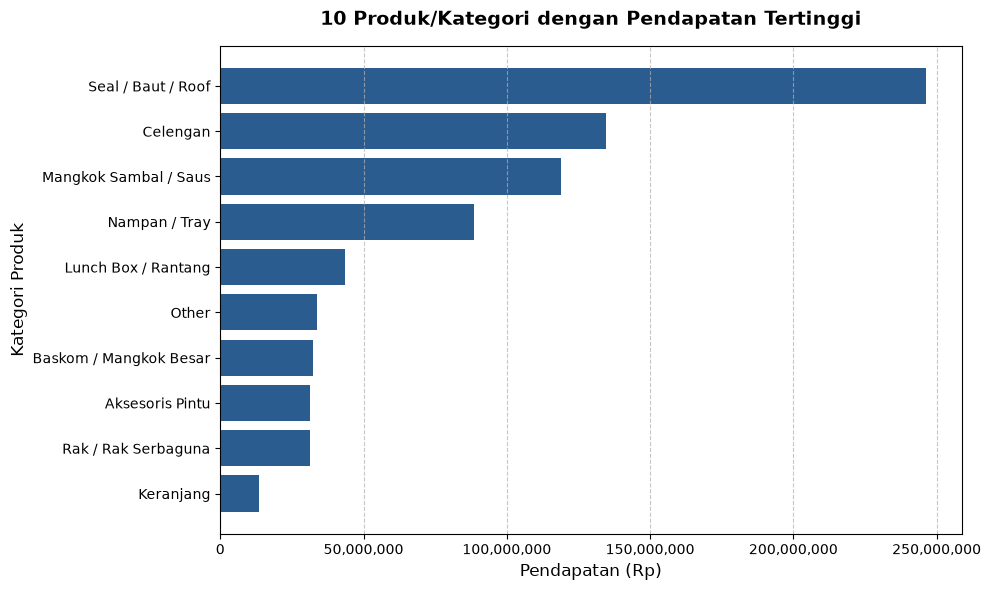

In [33]:
import matplotlib.pyplot as plt

# 1. Buat Dataframe top_product menggunakan kolom 'total_pembayaran' (huruf kecil)
top_product = (
    df.groupby("product_categories")["total_pembayaran"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# 2. Buat Grafik Batang Horizontal dengan Matplotlib
fig, ax = plt.subplots(figsize=(10, 6))

# Urutkan data agar nilai tertinggi berada di paling atas grafik
df_plot = top_product.sort_values(by="total_pembayaran", ascending=True)

# Gambar grafik
bars = ax.barh(df_plot["product_categories"], df_plot["total_pembayaran"], color="#2b5c8f")

# Tambahkan Judul & Label
ax.set_title("10 Produk/Kategori dengan Pendapatan Tertinggi", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Pendapatan (Rp)", fontsize=12)
ax.set_ylabel("Kategori Produk", fontsize=12)

# Format angka sumbu X agar ada pemisah ribuan
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Pertanyaan 2
**Bagaimana tren penjualan setiap tahun?**

Analisis ini dilakukan dengan melihat total pendapatan pada setiap tahun. Dengan membandingkan nilai pendapatan antar tahun, dapat diketahui apakah penjualan mengalami peningkatan atau penurunan.

In [39]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Buat kolom 'year' langsung dari tanggal transaksi (order_date)
# (Menggunakan errors="coerce" agar aman jika ada format tanggal yang aneh)
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["year"] = df["order_date"].dt.year

# 2. Hitung total penjualan per tahun
yearly_sales = (
    df.groupby("year")["total_pembayaran"]
    .sum()
    .reset_index()
)
# Tampilkan tabel hasil
display(yearly_sales)

,year,total_pembayaran
0,2023.0,23357121
1,2024.0,478801256
2,2025.0,435448645


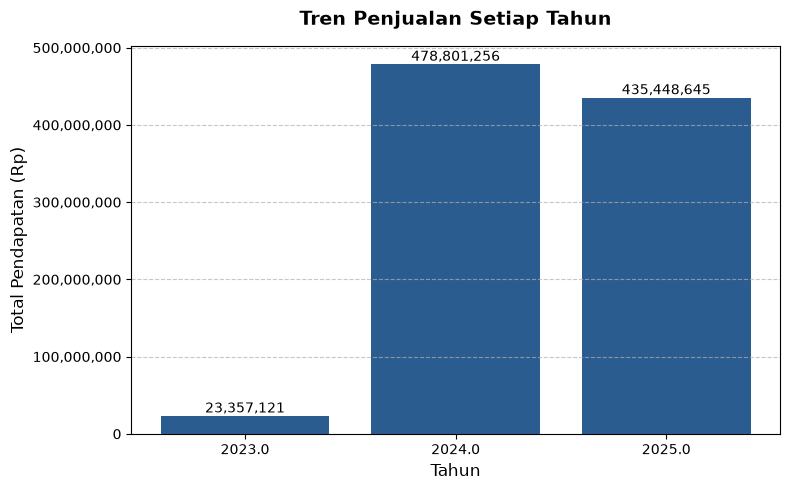

In [36]:
import matplotlib.pyplot as plt

# 1. Buat grafik batang
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    yearly_sales["year"].astype(str), 
    yearly_sales["total_pembayaran"], 
    color="#2b5c8f"
)

# 2. Tambahkan label angka di atas setiap batang
for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2, 
        yval, 
        f'{yval:,.0f}', 
        ha='center', 
        va='bottom', 
        fontsize=10
    )

# 3. Judul dan label sumbu
ax.set_title("Tren Penjualan Setiap Tahun", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Tahun", fontsize=12)
ax.set_ylabel("Total Pendapatan (Rp)", fontsize=12)

# Format angka pada sumbu Y
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Pertanyaan 3
**Kategori apa yang paling banyak dibeli di wilayah Kabupaten Bogor?**

Analisis ini dilakukan dengan mengambil transaksi yang berasal dari Kabupaten Bogor, kemudian menghitung jumlah produk yang dibeli untuk setiap kategori.

In [41]:
import matplotlib.pyplot as plt

# 1. Cari kolom lokasi secara otomatis
possible_cols = [c for c in df.columns if any(k in c.lower() for k in ["city", "kota", "alamat", "location", "customer"])]

if not possible_cols:
    print("Kolom lokasi tidak ditemukan. Silakan cek hasil print(df.columns.tolist()) terlebih dahulu.")
else:
    # Gunakan kolom lokasi pertama yang ditemukan
    city_col = possible_cols[0]
    print(f"Menggunakan kolom lokasi: '{city_col}'")

    # 2. Filter transaksi Bogor
    bogor = df[df[city_col].astype(str).str.contains("bogor", case=False, na=False)]

    # 3. Hitung total pendapatan per kategori di Bogor
    bogor_category = (
        bogor.groupby("product_categories")["total_pembayaran"]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    display(bogor_category.head(10))


Menggunakan kolom lokasi: 'kota_kabupaten'


,product_categories,total_pembayaran
0,Seal / Baut / Roof,21818805
1,Celengan,10367660
2,Lunch Box / Rantang,5360434
3,Mangkok Sambal / Saus,4665137
4,Baskom / Mangkok Besar,3308634
5,Aksesoris Pintu,2632064
6,Nampan / Tray,1929165
7,Other,1510969
8,Rak / Rak Serbaguna,1340135
9,Tempat Nasi,1126503


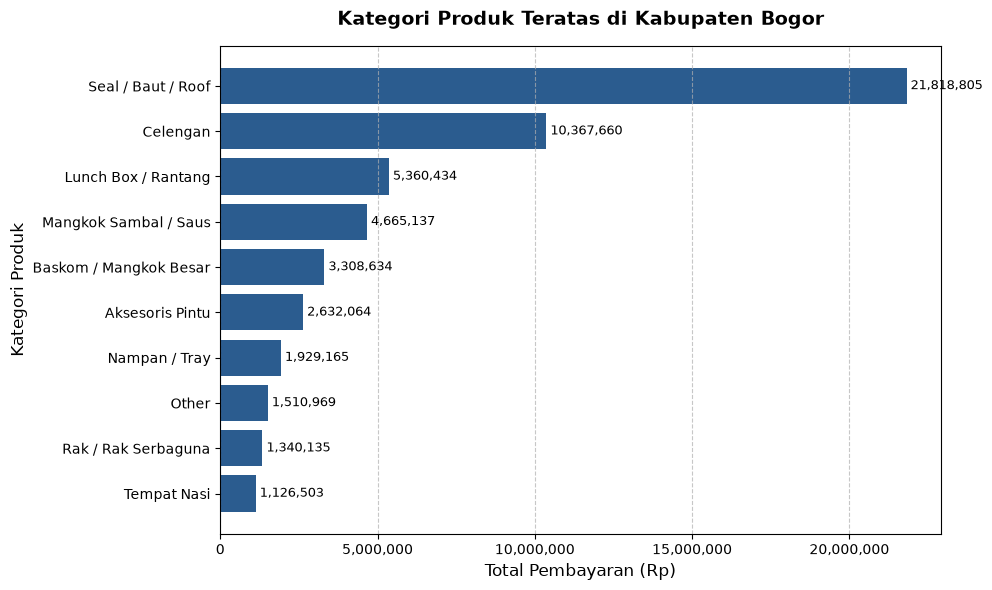

In [42]:
import matplotlib.pyplot as plt

# 1. Ambil 10 kategori teratas dan urutkan dari bawah ke atas
df_plot = bogor_category.head(10).sort_values(by="total_pembayaran", ascending=True)

# 2. Buat grafik batang horizontal
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df_plot["product_categories"], df_plot["total_pembayaran"], color="#2b5c8f")

# 3. Tambahkan label angka di samping setiap batang
for bar in bars:
    xval = bar.get_width()
    ax.text(
        xval, 
        bar.get_y() + bar.get_height()/2, 
        f' {xval:,.0f}', 
        ha='left', 
        va='center', 
        fontsize=9
    )

# 4. Atur Judul dan Label
ax.set_title("Kategori Produk Teratas di Kabupaten Bogor", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Total Pembayaran (Rp)", fontsize=12)
ax.set_ylabel("Kategori Produk", fontsize=12)

# Format angka sumbu X dan grid
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Hasil Analisis

Berdasarkan grafik, kategori dengan jumlah pembelian paling tinggi di Kabupaten Bogor dapat diketahui dari nilai jumlah produk terjual. Kategori tersebut menunjukkan produk yang paling banyak dibeli oleh pelanggan di wilayah Kabupaten Bogor.

### Analisis Pendapatan Berdasarkan Kategori

Analisis ini digunakan untuk mengetahui kategori produk mana yang memberikan kontribusi pendapatan paling besar.

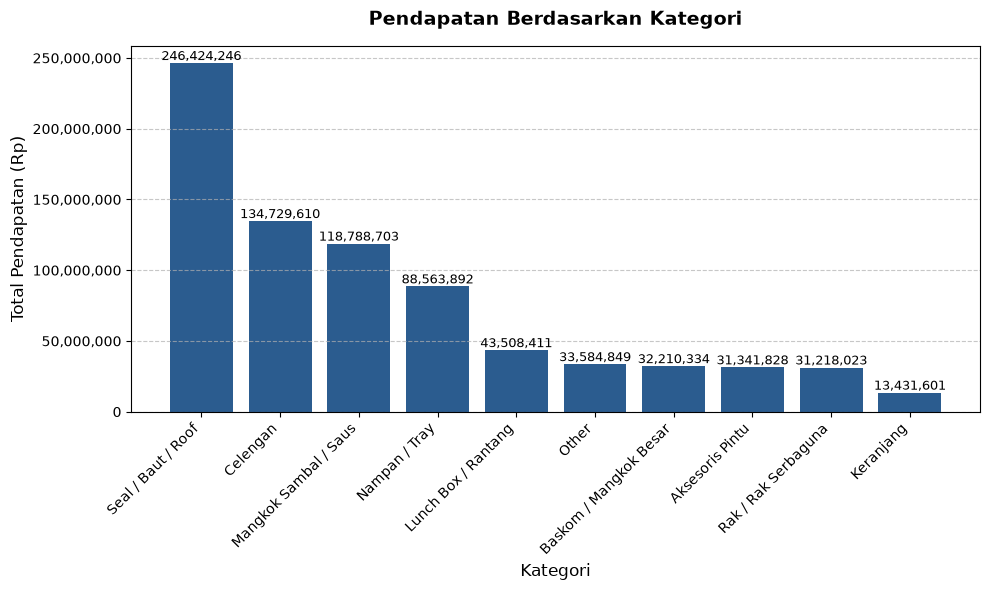

In [43]:
import matplotlib.pyplot as plt

# 1. Agregasi total pendapatan per kategori
category_sales = (
    df.groupby("product_categories")["total_pembayaran"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Ambil 10 kategori teratas untuk tampilan yang rapi
top_categories = category_sales.head(10)

# 2. Buat grafik batang vertikal
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    top_categories["product_categories"], 
    top_categories["total_pembayaran"], 
    color="#2b5c8f"
)

# Tambahkan label nilai di atas batang
for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2, 
        yval, 
        f'{yval:,.0f}', 
        ha='center', 
        va='bottom', 
        fontsize=9,
        rotation=0
    )

# Atur Judul dan Label
ax.set_title("Pendapatan Berdasarkan Kategori", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Kategori", fontsize=12)
ax.set_ylabel("Total Pendapatan (Rp)", fontsize=12)

# Miringkan label kategori agar tidak bertumpukan
plt.xticks(rotation=45, ha='right')

# Format angka sumbu Y
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Analisis Pendapatan Berdasarkan Wilayah

Analisis ini digunakan untuk mengetahui wilayah yang memberikan pendapatan terbesar.

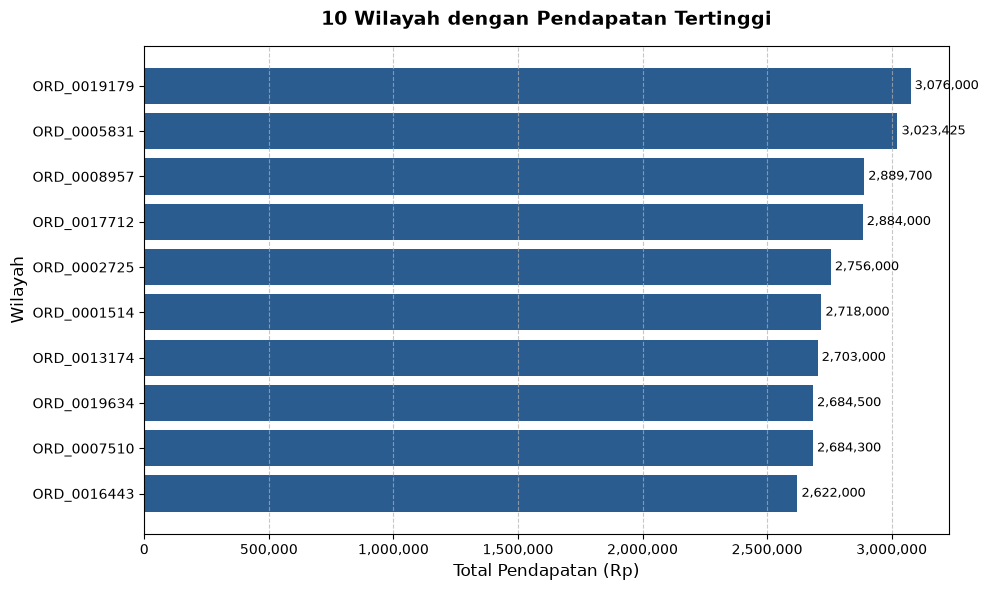

In [45]:
import matplotlib.pyplot as plt

# 1. Cek nama kolom lokasi yang tersedia
city_col = "city" if "city" in df.columns else ("kota" if "kota" in df.columns else df.columns[0])

# 2. Hitung 10 wilayah dengan pendapatan tertinggi
region_sales = (
    df.groupby(city_col)["total_pembayaran"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# 3. Urutkan dari nilai terkecil ke terbesar untuk grafik horizontal
df_plot = region_sales.sort_values(by="total_pembayaran", ascending=True)

# 4. Buat grafik batang horizontal
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df_plot[city_col], df_plot["total_pembayaran"], color="#2b5c8f")

# Tambahkan label angka di samping setiap batang
for bar in bars:
    xval = bar.get_width()
    ax.text(
        xval, 
        bar.get_y() + bar.get_height() / 2, 
        f' {xval:,.0f}', 
        ha='left', 
        va='center', 
        fontsize=9
    )

# Atur Judul dan Label
ax.set_title("10 Wilayah dengan Pendapatan Tertinggi", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Total Pendapatan (Rp)", fontsize=12)
ax.set_ylabel("Wilayah", fontsize=12)

# Format sumbu X dan grid
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Kesimpulan

Berdasarkan hasil analisis dan visualisasi data e-commerce, dapat diketahui produk yang memiliki pendapatan paling tinggi, perkembangan penjualan dari tahun ke tahun, serta kategori produk yang paling banyak dibeli di Kabupaten Bogor.

Hasil analisis ini dapat digunakan untuk melihat produk dan kategori yang memiliki performa baik serta mengetahui perkembangan penjualan berdasarkan waktu dan wilayah. Dengan melihat hasil tersebut, perusahaan dapat lebih mudah menentukan produk yang perlu diprioritaskan dan wilayah yang memiliki potensi penjualan lebih tinggi.